# Готовые представления и классификация обращений

На этот раз текст будет преобразовывать предобученный rubert-tiny2. Мы посмотрим, что возвращает его токенизатор и энкодер, получим по одному вектору на обращение и обучим знакомую логистическую регрессию. Затем сравним её ошибки с символьным TF-IDF.

In [1]:
from pathlib import Path
import os
import json
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Находим корень раздачи независимо от места запуска Jupyter.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "requests.csv").exists())
DATA = ROOT / "data"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(42)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.figsize": (8, 4)})


## Загрузка энкодера

Используем модель и токенизатор из подготовленного комплекта. Веса энкодера останутся фиксированными. Первую специальную позицию CLS возьмём по рекомендации автора модели; далее будем проверять её наличие, форму результата и нормировку.

Инструкция по подготовке файлов находится в START. Здесь начнём с одного короткого текста, чтобы увидеть данные, с которыми предстоит работать.

In [2]:
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay, classification_report

torch.set_num_threads(4)
MODEL_ROOT = Path(os.environ.get("NLP_MODELS_DIR", ROOT / ".cache" / "models"))
MODEL_DIR = MODEL_ROOT / "encoder"
if not (MODEL_DIR / "config.json").exists():
    raise FileNotFoundError("Сначала выполните scripts/prepare_models.py при доступном интернете")
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, local_files_only=True)
encoder, loading_info = AutoModel.from_pretrained(MODEL_DIR, local_files_only=True,
                                                 dtype=torch.float32, output_loading_info=True)
if loading_info["missing_keys"] or loading_info["mismatched_keys"] or loading_info["error_msgs"]:
    raise RuntimeError("Некорректная загрузка весов энкодера")
assert all(k.startswith("cls.") for k in loading_info["unexpected_keys"])
encoder.eval(); encoder.requires_grad_(False)
print("Размерность:", encoder.config.hidden_size, "Слоёв:", encoder.config.num_hidden_layers)

df = pd.read_csv(DATA / "requests.csv", keep_default_na=False)
parts = {name: df[df["split"].eq(name)].copy() for name in ["train", "validation", "test"]}
labels = sorted(df["label"].unique())


D:\AIS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 55/55 [00:00<00:00, 10387.55it/s]


[transformers] BertModel LOAD REPORT from: D:\AIS\.cache\models\encoder
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Размерность: 312 Слоёв: 3


In [3]:
demo_batch = tokenizer(["Как продлить книгу?"], return_tensors="pt")
print(tokenizer.convert_ids_to_tokens(demo_batch["input_ids"][0].tolist()))
with torch.inference_mode():
    demo_hidden = encoder(**demo_batch).last_hidden_state
print("Вход:", tuple(demo_batch["input_ids"].shape))
print("Выход:", tuple(demo_hidden.shape))

['[CLS]', 'Как', 'продлить', 'книгу', '?', '[SEP]']
Вход: (1, 6)
Выход: (1, 6, 312)


Первая ось выхода относится к текстам пакета, вторая — к токенам, третья — к 312 координатам скрытого представления. Найдите CLS в списке токенов. В следующем опыте появятся несколько текстов разной длины и padding.

## 1. Токены и длина входа

Для трёх строк из заготовки создайте `token_batch` с `padding=True`, `truncation=True`, `max_length=128`, `return_tensors="pt"`. Выведите формы полей, названия токенов и маску каждой строки. Убедитесь, что первая позиция — ожидаемый CLS.

Для всех обращений корпуса получите полные длины до усечения в массиве `lengths`. Число значений больше 128 сохраните как целое `truncated_count`. Учитывайте специальные позиции. Чем отличается добавление padding от усечения?

In [4]:
examples = ["Как продлить книгу?", "Не работает личный кабинет.", "Спасибо"]
token_batch = tokenizer(examples, padding=True, truncation=True, max_length=128, return_tensors="pt")
print({k: tuple(v.shape) for k, v in token_batch.items()})
for ids, mask in zip(token_batch["input_ids"], token_batch["attention_mask"]):
    print(tokenizer.convert_ids_to_tokens(ids.tolist()))
    print("Маска:", mask.tolist())
lengths = np.array([len(ids) for ids in tokenizer(df["text"].tolist(), truncation=False)["input_ids"]])
truncated_count = int((lengths > 128).sum())
print("Полные длины min/max:", lengths.min(), lengths.max(), "Усечённых:", truncated_count)

{'input_ids': (3, 7), 'token_type_ids': (3, 7), 'attention_mask': (3, 7)}
['[CLS]', 'Как', 'продлить', 'книгу', '?', '[SEP]', '[PAD]']
Маска: [1, 1, 1, 1, 1, 1, 0]
['[CLS]', 'Не', 'работает', 'личный', 'кабинет', '.', '[SEP]']
Маска: [1, 1, 1, 1, 1, 1, 1]
['[CLS]', 'Спасибо', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
Маска: [1, 1, 1, 0, 0, 0, 0]
Полные длины min/max: 8 21 Усечённых: 0


In [5]:
assert token_batch["input_ids"].shape[0] == 3
assert token_batch["input_ids"].shape == token_batch["attention_mask"].shape
assert (token_batch["input_ids"][:,0] == tokenizer.cls_token_id).all()
assert len(lengths) == len(df) and 0 <= truncated_count <= len(df)

В основном корпусе длины от 8 до 21, усечений нет. Поэтому ошибки этих 600 обращений нельзя объяснять потерей конца при пределе 128. Реальные токены определяются загруженным словарём, а не примером из другой модели.

## 2. По одному вектору на текст

Напишите `encode_texts(texts, batch_size=16)`. Обрабатывайте тексты пакетами с прежними настройками токенизатора. Передайте модели все поля пакета, возьмите `hidden[:, 0, :]`, нормируйте по оси признаков `dim=1` и объедините строки в исходном порядке. Используйте `eval()` и `torch.inference_mode()`; веса уже заморожены.

Пустой список должен возвращать массив формы `(0, 312)`. Для непустого результата первая ось равна числу текстов. Создайте `features` — словарь массивов для train, validation, test. Покажите их формы. Что изменится при ошибочной записи `hidden[0, 0, :]`?

In [6]:
def encode_texts(texts, batch_size=16):
    texts = list(texts)
    if batch_size < 1 or not all(isinstance(t, str) for t in texts):
        raise ValueError("Нужен положительный batch_size и список строк")
    if not texts:
        return np.empty((0, encoder.config.hidden_size), dtype=np.float32)
    encoder.eval()
    chunks = []
    with torch.inference_mode():
        for start in range(0, len(texts), batch_size):
            batch = tokenizer(texts[start:start+batch_size], padding=True, truncation=True,
                              max_length=128, return_tensors="pt")
            hidden = encoder(**batch).last_hidden_state
            vector = torch.nn.functional.normalize(hidden[:,0,:], dim=1)
            chunks.append(vector.cpu().numpy())
    return np.concatenate(chunks, axis=0)

features = {name: encode_texts(part["text"].tolist()) for name, part in parts.items()}
print({name: value.shape for name, value in features.items()})


{'train': (360, 312), 'validation': (120, 312), 'test': (120, 312)}


In [7]:
for name, part in parts.items():
    assert features[name].shape == (len(part), 312)
    assert np.isfinite(features[name]).all()
    assert np.allclose(np.linalg.norm(features[name], axis=1), 1, atol=1e-5)
assert not encoder.training
assert all(not p.requires_grad for p in encoder.parameters())
assert encode_texts([]).shape == (0,312)

Формы 360×312, 120×312, 120×312. Запись с двумя скалярными индексами оставляет только первую строку пакета. Нормировка по dim=1 задаёт отдельный знаменатель для каждого текста.

## 3. Соседний текст и padding

Сравните «Как продлить книгу?» отдельно и в пакете с более длинным обращением. Запишите максимальную абсолютную разницу в `batch_difference`; она должна быть меньше 1e-5. Повторите отдельное кодирование той же строки.

Для ручной матрицы `H = [[1, 0], [0, 1], [9, 9]]` и маски `[1, 1, 0]` вычислите обычное среднее и `masked_mean`. Почему исключение padding из внимания не позволяет автоматически усреднять все выходные позиции? Основной классификатор продолжает использовать CLS.

In [8]:
short = "Как продлить книгу?"
single = encode_texts([short])
paired = encode_texts([short, "Не могу войти в личный кабинет после смены пароля, появляется ошибка."])
repeat = encode_texts([short])
batch_difference = float(np.max(np.abs(single[0] - paired[0])))
print("Разница отдельного/пакетного:", batch_difference)
assert np.allclose(single, repeat, atol=1e-6)
H = np.array([[1.,0.],[0.,1.],[9.,9.]])
mask = np.array([1.,1.,0.])
masked_mean = (H * mask[:, None]).sum(axis=0) / mask.sum()
print("Обычное среднее:", H.mean(axis=0), "Masked mean:", masked_mean)

Разница отдельного/пакетного: 8.568167686462402e-08
Обычное среднее: [3.33333333 3.33333333] Masked mean: [0.5 0.5]


In [9]:
assert batch_difference < 1e-5
assert np.allclose(masked_mean, [0.5,0.5])

Разница кодирования порядка 10⁻⁷. Обычное среднее равно (10/3;10/3), masked mean — (0,5;0,5). Маска ключей не обязана занулять выход padding-позиции.

## 4. Два представления, один способ классификации

Обучите `embedding_clf=LogisticRegression(C=1,max_iter=1000,random_state=42)` на features["train"]. Классический `lexical` — Pipeline с char_wb(3,5), max_features=5000 и такой же регрессией. Оцените accuracy и macro-F1 по всем 6 меткам на validation/test. Конфигурации не меняются после просмотра чисел. `scores_table` содержит столбцы split, model, accuracy, macro_f1. `predictions` — словарь с ключами "tfidf" и "encoder" и массивами предсказаний теста. Постройте матрицу ошибок для encoder.

Сопоставьте общую accuracy с recall отдельных категорий. Какой класс потерял больше всего обращений?

,split,model,accuracy,macro_f1
0,validation,tfidf,0.741667,0.742991
1,validation,encoder,0.800000,0.789283
2,test,tfidf,0.791667,0.765197
3,test,encoder,0.900000,0.886331


              precision    recall  f1-score   support

   admission       1.00      0.40      0.57        20
   dormitory       1.00      1.00      1.00        20
          it       1.00      1.00      1.00        20
     library       0.87      1.00      0.93        20
 scholarship       1.00      1.00      1.00        20
       study       0.69      1.00      0.82        20

    accuracy                           0.90       120
   macro avg       0.93      0.90      0.89       120
weighted avg       0.93      0.90      0.89       120



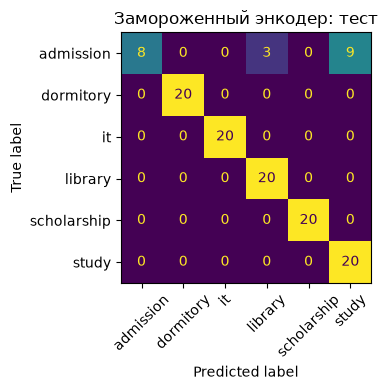

In [10]:
embedding_clf = LogisticRegression(C=1, max_iter=1000, random_state=42)
embedding_clf.fit(features["train"], parts["train"]["label"])
lexical = Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), max_features=5000)),
                    ("clf", LogisticRegression(C=1, max_iter=1000, random_state=42))])
lexical.fit(parts["train"]["text"], parts["train"]["label"])
rows, predictions = [], {}
for split in ["validation", "test"]:
    pairs = {"tfidf": lexical.predict(parts[split]["text"]),
             "encoder": embedding_clf.predict(features[split])}
    for name, pred in pairs.items():
        rows.append({"split": split, "model": name,
                     "accuracy": accuracy_score(parts[split]["label"], pred),
                     "macro_f1": f1_score(parts[split]["label"], pred, labels=labels, average="macro", zero_division=0)})
        if split == "test": predictions[name] = pred
scores_table = pd.DataFrame(rows)
display(scores_table)
print(classification_report(parts["test"]["label"], predictions["encoder"], labels=labels, zero_division=0))
ConfusionMatrixDisplay.from_predictions(parts["test"]["label"], predictions["encoder"], labels=labels, xticks_rotation=45, colorbar=False)
plt.title("Замороженный энкодер: тест"); plt.tight_layout(); plt.show()

In [11]:
assert set(predictions) == {"tfidf", "encoder"}
assert all(len(p) == len(parts["test"]) for p in predictions.values())
assert scores_table["macro_f1"].between(0,1).all()
assert all(not p.requires_grad for p in encoder.parameters())

У энкодера тестовая accuracy 0,90, macro-F1 ≈ 0,8863. Однако recall поступления 0,40: 12 из 20 строк этой категории направлены в другие отделы. Матрица ошибок раскрывает то, что скрыто в общем проценте.

## 5. Читаем удачные и ошибочные решения

Создайте `error_cases` для всех тестовых строк с колонками `id`, `group_id`, `text`, `label`, `tfidf`, `encoder`. Затем отдельно отберите до пяти разных групп: хотя бы одну ошибку энкодера и одно исправление ошибки TF-IDF, если они есть.

Прочитайте обращения вместе с метками. В чём заключается затруднение: близкие темы, граница организационных категорий, недостаток контекста? Для гипотезы о влиянии слова предложите отдельную проверку. Один удачный или ошибочный пример сам по себе не объясняет механизм модели.

In [12]:
error_cases = parts["test"].assign(tfidf=predictions["tfidf"], encoder=predictions["encoder"])
failures = error_cases[error_cases["encoder"].ne(error_cases["label"])].drop_duplicates("group_id").head(3)
improved = error_cases[error_cases["encoder"].eq(error_cases["label"]) & error_cases["tfidf"].ne(error_cases["label"])]
improved = improved[~improved["group_id"].isin(failures["group_id"])].drop_duplicates("group_id").head(2)
for row in pd.concat([failures, improved]).itertuples():
    print({"group": row.group_id, "text": row.text, "true": row.label, "tfidf": row.tfidf, "encoder": row.encoder})

{'group': 'admission-17', 'text': 'Как изменить выбранное направление в заявлении абитуриента?', 'true': 'admission', 'tfidf': 'admission', 'encoder': 'study'}
{'group': 'admission-19', 'text': 'Здравствуйте! Можно ли отправить пакет документов по почте?', 'true': 'admission', 'tfidf': 'admission', 'encoder': 'library'}
{'group': 'admission-20', 'text': 'Кто консультирует по вступительному собеседованию?', 'true': 'admission', 'tfidf': 'admission', 'encoder': 'study'}
{'group': 'library-19', 'text': 'Не могу найти монографию в списке доступной литературы.', 'true': 'library', 'tfidf': 'it', 'encoder': 'library'}
{'group': 'library-20', 'text': 'Мне нужна помощь в подборе источников для курсовой.', 'true': 'library', 'tfidf': 'it', 'encoder': 'library'}


In [13]:
assert len(error_cases) == len(parts["test"])
assert {"text","label","tfidf","encoder","group_id"} <= set(error_cases.columns)

В показанных вариантах library-19/20 энкодер правильно выбирает библиотеку. У admission-17/20 остаются ошибки в сторону study. Вариант admission-19 с приветствием относится к неоднозначной просьбе о документах; нужно обсудить достаточность самого входа.

## Просьба осталась за пределом входа

В основном корпусе усечений не было. Теперь создадим отдельный длинный пример с просьбой в конце. До запуска предскажите, увидит ли модель эту просьбу при прежнем max_length. После усечения прочитайте сохранённый текст.

In [14]:
# Длинный диагностический вход: важная просьба только в конце.
long_text = "Уточняю ранее отправленный вопрос. " * 80 + "Как продлить книгу?"
full_ids = tokenizer(long_text, truncation=False)["input_ids"]
cut_ids = tokenizer(long_text, truncation=True, max_length=128)["input_ids"]
cut_text = tokenizer.decode(cut_ids, skip_special_tokens=True)
print("Полная длина:", len(full_ids), "После усечения:", len(cut_ids))
print("Конец после усечения:", cut_text[-150:])
print("Слово 'книгу' сохранилось:", "книгу" in cut_text)
assert len(full_ids)>128 and len(cut_ids)==128 and "книгу" not in cut_text


Полная длина: 566 После усечения: 128
Конец после усечения: ый вопрос. Уточняю ранее отправленный вопрос. Уточняю ранее отправленный вопрос. Уточняю ранее отправленный вопрос. Уточняю ранее отправленный вопрос.
Слово 'книгу' сохранилось: False


## Что получилось

Все основные обращения помещаются в 128 токенов: реальные длины со специальными позициями от 8 до 21. Признаки имеют формы 360×312, 120×312, 120×312. Одинаковая короткая строка отдельно и рядом с длинной различается примерно на 10⁻⁷, что укладывается в допуск. Энкодер фиксирован, новую классификацию выучила логистическая регрессия.

На validation TF-IDF дал accuracy 0,7417 и macro-F1 ≈ 0,7430, энкодер — 0,8000 и 0,7893. На test значения равны 0,7917/0,7652 и 0,9000/0,8863. При этом все 12 ошибок энкодера относятся к поступлению: recall admission 0,40. В остальных пяти категориях recall 1 на данном тесте.

В admission-17 просьба изменить направление в заявлении абитуриента была правильно распознана TF-IDF, но энкодер выбрал study. В admission-20 аналогичное расхождение произошло на консультации по вступительному собеседованию. Указания на поступление не оказались достаточными для этого фиксированного представления и обученной головы.

В показанном варианте admission-19 с приветствием вопрос о почтовой отправке документов направлен энкодером в library. Авторская метка — admission, однако сама просьба допускает разные процедуры. Это повод проверить полноту контекста и правила разметки. В показанных вариантах library-19 о монографии и library-20 о подборе источников TF-IDF ответил it, а энкодер правильно ответил library.

Диагностический длинный вход содержит 566 токенов; после ограничения осталось 128. Слово «книгу» и сама просьба из конца исчезли. Это отдельный опыт потери входа, он не объясняет ошибки короткого основного корпуса.

В ручном pooling обычное среднее равно (3,3333;3,3333), masked mean — (0,5;0,5). В основной классификации использован рекомендованный нормированный CLS. BIO для шести слов: B-PER, I-PER, O, O, B-ORG, I-ORG. Если извлечено только «Петрова», при точных границах это один FP и один FN. Эта разметка выполнена вручную, NER-модель в работе не обучалась.
